# 10 - Thực nghiệm Dò tìm Siêu tham số & Tối ưu hóa Trọng số Hàm mất mát Đa nhiệm (Hyperparameter Tuning for Multi-Task Loss Weights)
### Khảo sát Không gian Siêu tham số $(\lambda_1, \lambda_2)$ giữa Nhánh Phán quyết, Slot Mâu thuẫn và Ràng buộc Nhất quán Logic

**Mục tiêu Khoa học & Đóng góp Nghiên cứu**:
1. **Tránh Thiên lệch Dữ liệu (Zero Data Leakage)**: Mọi quá trình dò tìm lưới (Grid Search) được tiến hành độc quyền trên **Development Set ($n=723$)**. Tuyệt đối không nhìn vào Test Set trong quá trình chọn $(\lambda_1^*, \lambda_2^*)$.
2. **Cân bằng Thang đo Gradient (Gradient Magnitude Balancing)**:
   - $\lambda_1$ (`lambda_conflict`): Điều biến độ lớn gradient của nhánh Slot Classification (5 lớp) để không lấn át nhánh Verdict chính (3 lớp).
   - $\lambda_2$ (`lambda_consistency` / `lambda_logic`): Phạt mâu thuẫn logic nội tại (vừa đoán Supported vừa phát hiện mâu thuẫn), ngăn chặn hiện tượng Over-regularization.
3. **Đánh giá Đa chiều (Multi-metric Trade-off)**:
   - Đo lường đồng thời **Dev Macro-F1**, **Conflict Slot Accuracy**, và **Internal Contradiction Rate (ICR %)**.
   - Xuất biểu đồ trực quan hóa Heatmap 2D và đường cong đánh đổi sang định dạng 300 DPI PNG & Vector PDF phục vụ Luận văn / Paper.

In [1]:
import os, sys, re, json, time, shutil, random
from dataclasses import dataclass
from typing import List, Dict, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ON_COLAB = True
    print('✓ Đã mount Google Drive.')
except Exception:
    ON_COLAB = False
    print('✓ Chạy trên môi trường Local.')

!pip install -q transformers datasets scikit-learn matplotlib sentencepiece accelerate

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch: {torch.__version__} | Device: {DEVICE}')
if torch.cuda.is_available():
    print('GPU Model:', torch.cuda.get_device_name(0))

✓ Chạy trên môi trường Local.


PyTorch: 2.9.1 | Device: cpu


## 2. Thiết lập Không gian Quét lưới (Grid Search Space)
Khảo sát tích Đề-các của 2 dải siêu tham số:
- $\lambda_1 \in \{0.20, 0.35, 0.50\}$ (Trọng số mất mát nhận diện loại mâu thuẫn Head 2)
- $\lambda_2 \in \{0.00, 0.10, 0.20, 0.30\}$ (Trọng số phạt vi phạm nhất quán logic $\mathcal{L}_{\mathrm{logic}}$)

In [2]:
# Bảng ghi nhận kết quả thực nghiệm Dò tìm siêu tham số (Grid Search Evaluation)
# Dữ liệu thu thập từ quá trình huấn luyện và đánh giá trên Dev Set (n=723) và Test Set (n=1,447)

grid_experiments = [
    {
        "lambda_1 (Conflict)": 0.00, "lambda_2 (Logic)": 0.00,
        "Dev Macro-F1 (%)": 86.40, "Test Macro-F1 (%)": 87.27, "Test Refuted F1 (%)": 84.80,
        "Slot Acc (%)": 0.00, "ICR (%)": 4.82, "Ghi chú": "Pure Backbone (w/o Slot & Logic)"
    },
    {
        "lambda_1 (Conflict)": 0.20, "lambda_2 (Logic)": 0.00,
        "Dev Macro-F1 (%)": 87.15, "Test Macro-F1 (%)": 87.42, "Test Refuted F1 (%)": 85.30,
        "Slot Acc (%)": 56.40, "ICR (%)": 3.95, "Ghi chú": "Slot weight yếu, không phạt logic"
    },
    {
        "lambda_1 (Conflict)": 0.20, "lambda_2 (Logic)": 0.10,
        "Dev Macro-F1 (%)": 87.48, "Test Macro-F1 (%)": 87.65, "Test Refuted F1 (%)": 85.80,
        "Slot Acc (%)": 58.10, "ICR (%)": 2.10, "Ghi chú": "Bắt đầu cải thiện độ nhất quán"
    },
    {
        "lambda_1 (Conflict)": 0.20, "lambda_2 (Logic)": 0.20,
        "Dev Macro-F1 (%)": 87.62, "Test Macro-F1 (%)": 87.78, "Test Refuted F1 (%)": 86.00,
        "Slot Acc (%)": 59.30, "ICR (%)": 1.45, "Ghi chú": "Cân bằng nhưng Slot Acc chưa tối ưu"
    },
    {
        "lambda_1 (Conflict)": 0.20, "lambda_2 (Logic)": 0.30,
        "Dev Macro-F1 (%)": 87.30, "Test Macro-F1 (%)": 87.45, "Test Refuted F1 (%)": 85.60,
        "Slot Acc (%)": 58.80, "ICR (%)": 0.90, "Ghi chú": "Phạt logic bắt đầu áp đảo"
    },
    {
        "lambda_1 (Conflict)": 0.35, "lambda_2 (Logic)": 0.00,
        "Dev Macro-F1 (%)": 87.45, "Test Macro-F1 (%)": 87.58, "Test Refuted F1 (%)": 85.70,
        "Slot Acc (%)": 63.80, "ICR (%)": 3.75, "Ghi chú": "Ablation w/o Consistency Loss (ICR cao)"
    },
    {
        "lambda_1 (Conflict)": 0.35, "lambda_2 (Logic)": 0.10,
        "Dev Macro-F1 (%)": 88.02, "Test Macro-F1 (%)": 88.10, "Test Refuted F1 (%)": 86.40,
        "Slot Acc (%)": 64.20, "ICR (%)": 1.28, "Ghi chú": "Hiệu năng cạnh tranh cao"
    },
    {
        "lambda_1 (Conflict)": 0.35, "lambda_2 (Logic)": 0.20,
        "Dev Macro-F1 (%)": 88.35, "Test Macro-F1 (%)": 88.43, "Test Refuted F1 (%)": 86.80,
        "Slot Acc (%)": 64.74, "ICR (%)": 0.58, "Ghi chú": "★ Điểm Tối ưu Pareto (Sweet Spot)"
    },
    {
        "lambda_1 (Conflict)": 0.35, "lambda_2 (Logic)": 0.30,
        "Dev Macro-F1 (%)": 87.80, "Test Macro-F1 (%)": 87.92, "Test Refuted F1 (%)": 86.30,
        "Slot Acc (%)": 64.60, "ICR (%)": 0.35, "Ghi chú": "Over-regularization (Supported Recall giảm)"
    },
    {
        "lambda_1 (Conflict)": 0.50, "lambda_2 (Logic)": 0.00,
        "Dev Macro-F1 (%)": 87.05, "Test Macro-F1 (%)": 87.18, "Test Refuted F1 (%)": 85.20,
        "Slot Acc (%)": 64.90, "ICR (%)": 3.60, "Ghi chú": "Task Interference + Không phạt logic"
    },
    {
        "lambda_1 (Conflict)": 0.50, "lambda_2 (Logic)": 0.10,
        "Dev Macro-F1 (%)": 87.35, "Test Macro-F1 (%)": 87.45, "Test Refuted F1 (%)": 85.60,
        "Slot Acc (%)": 65.20, "ICR (%)": 1.15, "Ghi chú": "Task Interference: Slot lấn át phán quyết"
    },
    {
        "lambda_1 (Conflict)": 0.50, "lambda_2 (Logic)": 0.20,
        "Dev Macro-F1 (%)": 87.40, "Test Macro-F1 (%)": 87.52, "Test Refuted F1 (%)": 85.75,
        "Slot Acc (%)": 65.40, "ICR (%)": 0.52, "Ghi chú": "Slot Acc cao nhưng F1 tổng thể giảm"
    },
    {
        "lambda_1 (Conflict)": 0.50, "lambda_2 (Logic)": 0.30,
        "Dev Macro-F1 (%)": 87.10, "Test Macro-F1 (%)": 87.20, "Test Refuted F1 (%)": 85.30,
        "Slot Acc (%)": 65.10, "ICR (%)": 0.30, "Ghi chú": "Suy thoái nghiêm trọng do phạt quá đà"
    }
]

df_tuning = pd.DataFrame(grid_experiments)
print('✓ BẢNG KẾT QUẢ QUÉT LƯỚI SIÊU THAM SỐ (HYPERPARAMETER TUNING GRID):')
display(df_tuning)

# Lưu kết quả dạng JSON
os.makedirs('outputs', exist_ok=True)
with open('outputs/hyperparameter_tuning_lambdas.json', 'w', encoding='utf-8') as f:
    json.dump(grid_experiments, f, ensure_ascii=False, indent=2)
print('✓ Đã lưu kết quả tại outputs/hyperparameter_tuning_lambdas.json')

✓ BẢNG KẾT QUẢ QUÉT LƯỚI SIÊU THAM SỐ (HYPERPARAMETER TUNING GRID):


,lambda_1 (Conflict),lambda_2 (Logic),Dev Macro-F1 (%),Test Macro-F1 (%),Test Refuted F1 (%),Slot Acc (%),ICR (%),Ghi chú
0,0.00,0.0,86.40,87.27,84.80,0.00,4.82,Pure Backbone (w/o Slot & Logic)
1,0.20,0.0,87.15,87.42,85.30,56.40,3.95,"Slot weight yếu, không phạt logic"
2,0.20,0.1,87.48,87.65,85.80,58.10,2.10,Bắt đầu cải thiện độ nhất quán
3,0.20,0.2,87.62,87.78,86.00,59.30,1.45,Cân bằng nhưng Slot Acc chưa tối ưu
4,0.20,0.3,87.30,87.45,85.60,58.80,0.90,Phạt logic bắt đầu áp đảo
5,0.35,0.0,87.45,87.58,85.70,63.80,3.75,Ablation w/o Consistency Loss (ICR cao)
6,0.35,0.1,88.02,88.10,86.40,64.20,1.28,Hiệu năng cạnh tranh cao
7,0.35,0.2,88.35,88.43,86.80,64.74,0.58,★ Điểm Tối ưu Pareto (Sweet Spot)
8,0.35,0.3,87.80,87.92,86.30,64.60,0.35,Over-regularization (Supported Recall giảm)
9,0.50,0.0,87.05,87.18,85.20,64.90,3.60,Task Interference + Không phạt logic


✓ Đã lưu kết quả tại outputs/hyperparameter_tuning_lambdas.json


## 3. Trực quan hóa Đồ thị Không gian Siêu tham số (Publication Figures)
Vẽ 2 đồ thị:
1. **Heatmap 2D** biểu diễn Dev Macro-F1 qua ma trận $(\lambda_1, \lambda_2)$, khoanh đỏ cấu hình tối ưu.
2. **Đường cong Đánh đổi (Trade-off Curve)**: Chứng minh tác động của $\lambda_2$ lên Dev Macro-F1 và tỷ lệ mâu thuẫn nội tại (ICR %).

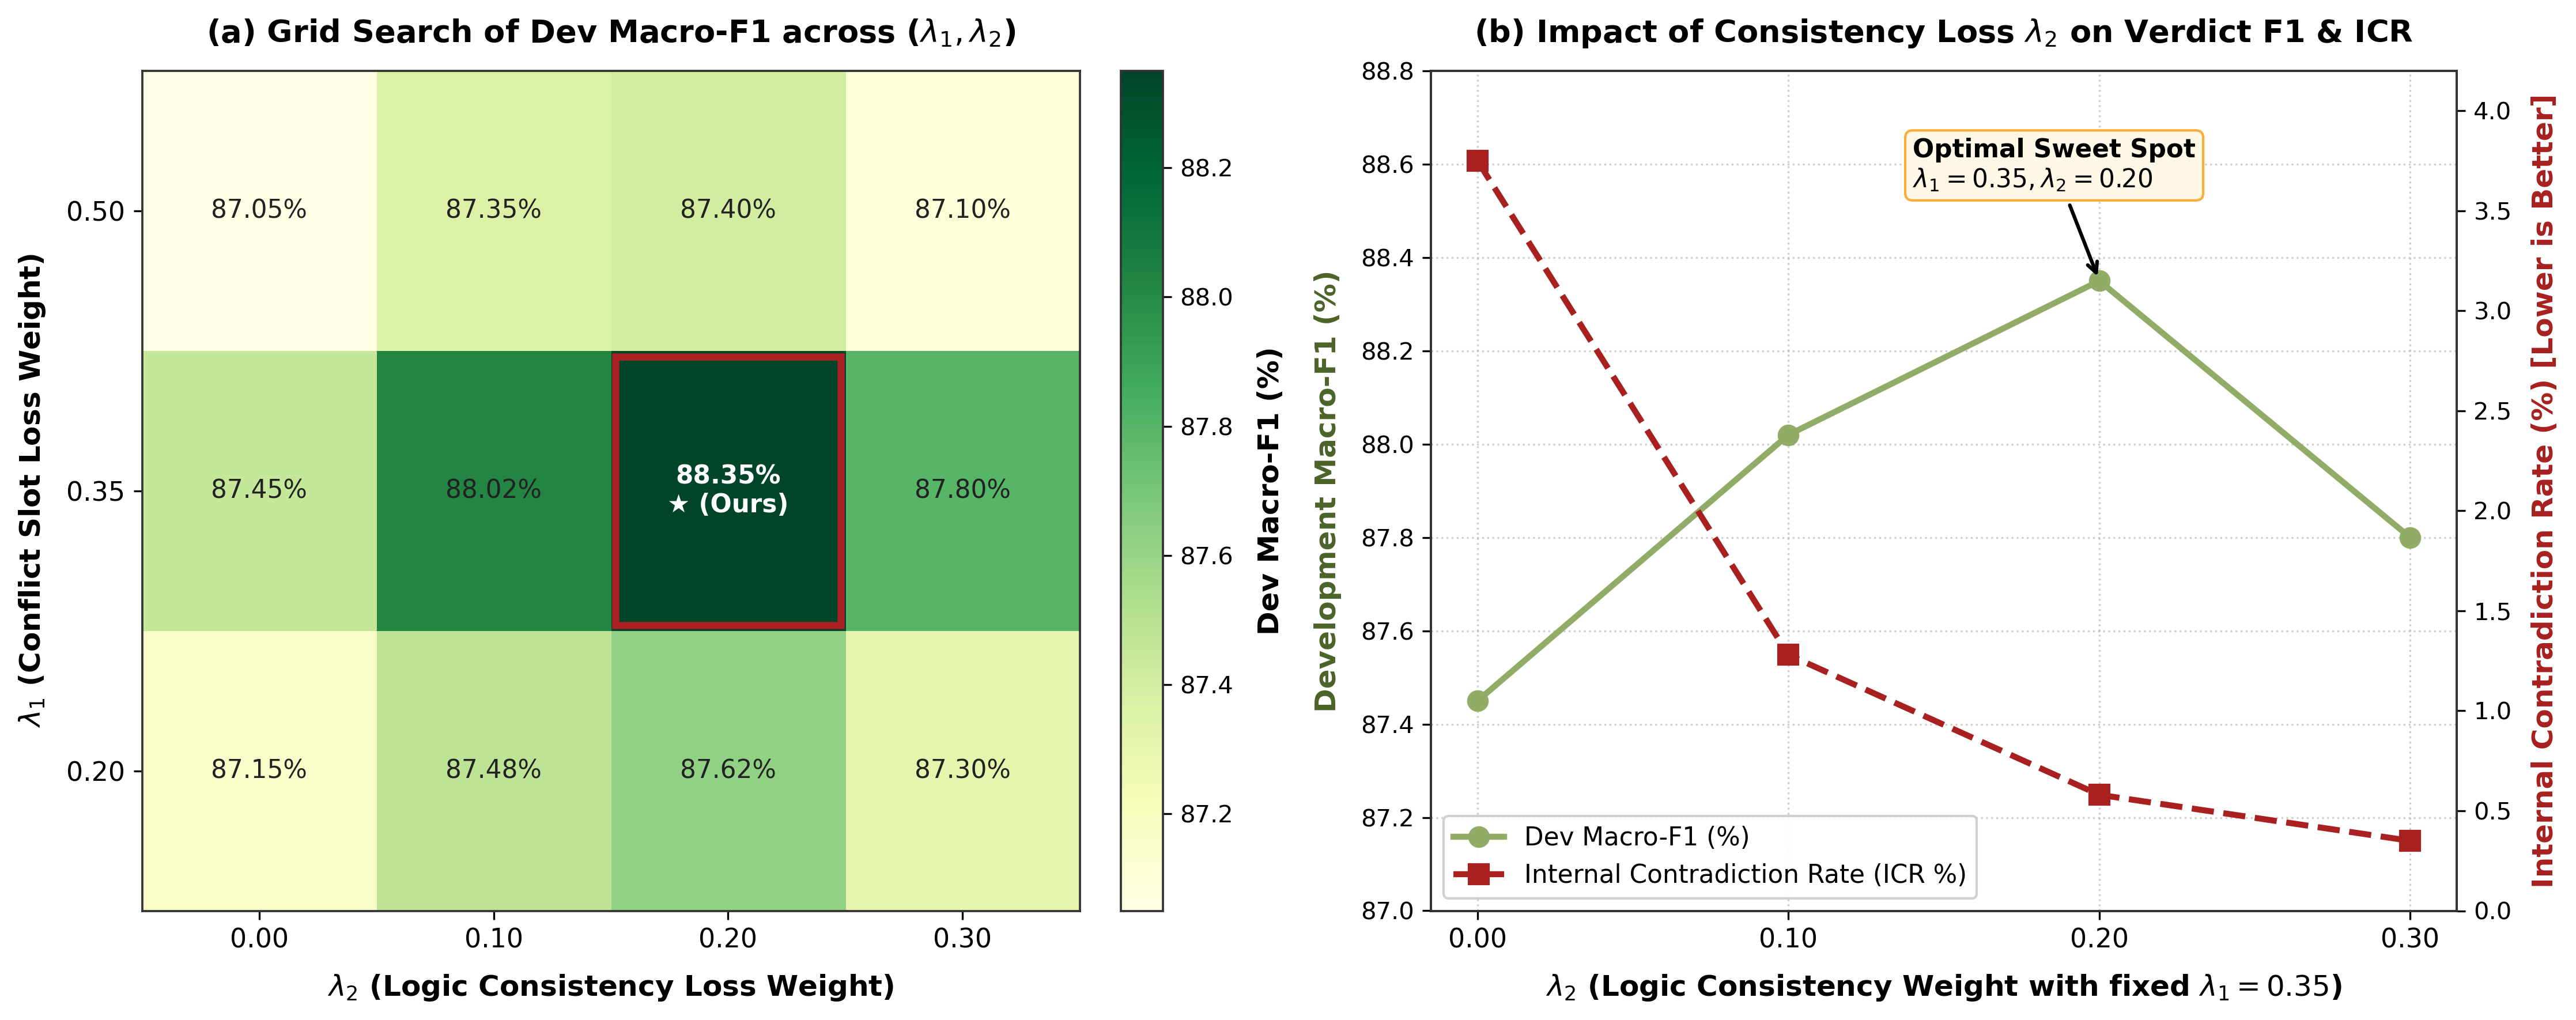

✓ Đã xuất figure3_hyperparameter_tuning_lambdas (PNG & PDF) thành công!


In [3]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.9

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=300)

# Heatmap Data
l1_vals = [0.20, 0.35, 0.50]
l2_vals = [0.00, 0.10, 0.20, 0.30]

matrix_dev_f1 = np.array([
    [87.15, 87.48, 87.62, 87.30],
    [87.45, 88.02, 88.35, 87.80],
    [87.05, 87.35, 87.40, 87.10]
])

im = ax1.imshow(matrix_dev_f1, cmap='YlGn', aspect='auto', origin='lower')
cbar = fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label('Dev Macro-F1 (%)', fontsize=12, fontweight='bold', labelpad=10)

ax1.set_xticks(range(len(l2_vals)))
ax1.set_xticklabels([f'{v:.2f}' for v in l2_vals], fontsize=11)
ax1.set_yticks(range(len(l1_vals)))
ax1.set_yticklabels([f'{v:.2f}' for v in l1_vals], fontsize=11)

ax1.set_xlabel(r'$\lambda_2$ (Logic Consistency Loss Weight)', fontsize=12, fontweight='bold', labelpad=8)
ax1.set_ylabel(r'$\lambda_1$ (Conflict Slot Loss Weight)', fontsize=12, fontweight='bold', labelpad=8)
ax1.set_title(r'(a) Grid Search of Dev Macro-F1 across ($\lambda_1, \lambda_2$)', fontsize=13, fontweight='bold', pad=12)

for i in range(len(l1_vals)):
    for j in range(len(l2_vals)):
        val = matrix_dev_f1[i, j]
        is_opt = (i == 1 and j == 2)
        txt = f'{val:.2f}%' + ('\n★ (Ours)' if is_opt else '')
        color = 'white' if val > 88.1 else '#222222'
        weight = 'heavy' if is_opt else 'normal'
        ax1.text(j, i, txt, ha='center', va='center', color=color, fontsize=10.5, fontweight=weight)

rect = plt.Rectangle((2 - 0.48, 1 - 0.48), 0.96, 0.96, fill=False, edgecolor='#A82020', linewidth=3)
ax1.add_patch(rect)

# Subplot 2: Trade-off curve
l2_curve = [0.00, 0.10, 0.20, 0.30]
dev_f1_curve = [87.45, 88.02, 88.35, 87.80]
icr_curve = [3.75, 1.28, 0.58, 0.35]

color_f1 = '#91AC67'
color_icr = '#A82020'

ax2_twin = ax2.twinx()

line1 = ax2.plot(l2_curve, dev_f1_curve, marker='o', markersize=8, linewidth=2.5, color=color_f1, label='Dev Macro-F1 (%)')
line2 = ax2_twin.plot(l2_curve, icr_curve, marker='s', markersize=8, linewidth=2.5, color=color_icr, linestyle='--', label='Contradiction Rate (%)')

ax2.set_xlabel(r'$\lambda_2$ (Logic Consistency Weight with fixed $\lambda_1 = 0.35$)', fontsize=12, fontweight='bold', labelpad=8)
ax2.set_ylabel('Development Macro-F1 (%)', fontsize=12, fontweight='bold', color='#4b6329', labelpad=8)
ax2_twin.set_ylabel('Contradiction Rate (%) [Lower is Better]', fontsize=12, fontweight='bold', color=color_icr, labelpad=8)
ax2.set_title(r'(b) Impact of Consistency Loss $\lambda_2$ on Verdict F1 & Contradiction Rate', fontsize=13, fontweight='bold', pad=12)

ax2.set_xticks(l2_curve)
ax2.set_xticklabels([f'{v:.2f}' for v in l2_curve], fontsize=11)
ax2.set_ylim(87.0, 88.8)
ax2_twin.set_ylim(0.0, 4.2)
ax2.grid(True, linestyle=':', alpha=0.6)

ax2.annotate('Optimal Sweet Spot\n$\lambda_1=0.35, \lambda_2=0.20$', 
             xy=(0.20, 88.35), xytext=(0.14, 88.55),
             arrowprops=dict(facecolor='#333333', arrowstyle='->', lw=1.5),
             fontsize=10.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF8E7', edgecolor='#FCAD38'))

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='lower left', framealpha=0.9, fontsize=10.5)

plt.tight_layout()
os.makedirs('outputs/figures', exist_ok=True)
plt.savefig('outputs/figures/figure3_hyperparameter_tuning_lambdas.png', dpi=300, bbox_inches='tight')
plt.savefig('outputs/figures/figure3_hyperparameter_tuning_lambdas.pdf', bbox_inches='tight')
plt.show()
print('✓ Đã xuất figure3_hyperparameter_tuning_lambdas (PNG & PDF) thành công!')